In [1]:
"""
To try the examples in the browser:
1. Type code in the input cell and press
   Shift + Enter to execute
2. Or copy paste the code, and click on
   the "Run" button in the toolbar
"""

# The standard way to import NumPy:
import numpy as np

In [2]:
# Create a 2-D array, set every second element in
# some rows and find max per row:

x = np.arange(15, dtype=np.int64).reshape(3, 5)
x[1:, ::2] = -99
x
# array([[  0,   1,   2,   3,   4],
#        [-99,   6, -99,   8, -99],
#        [-99,  11, -99,  13, -99]])

array([[  0,   1,   2,   3,   4],
       [-99,   6, -99,   8, -99],
       [-99,  11, -99,  13, -99]])

In [3]:
x.max(axis=1)
# array([ 4,  8, 13])

# Generate normally distributed random numbers:
rng = np.random.default_rng()
samples = rng.normal(size=2500)
samples

array([ 0.40361957, -0.05821055, -2.89609813, ...,  0.4287422 ,
        0.17045151, -0.55076346])

In [4]:
n1 = np.array([10, 20, 30, 40, 50])

In [5]:
type(n1)

numpy.ndarray

In [6]:
import pandas as pd

In [7]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"

In [10]:
df = pd.read_csv(url)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [29]:
df['model_year'].describe()

count    398.000000
mean      76.010050
std        3.697627
min       70.000000
25%       73.000000
50%       76.000000
75%       79.000000
max       82.000000
Name: model_year, dtype: float64

In [13]:
name = df['name']
name

0      chevrolet chevelle malibu
1              buick skylark 320
2             plymouth satellite
3                  amc rebel sst
4                    ford torino
                 ...            
393              ford mustang gl
394                    vw pickup
395                dodge rampage
396                  ford ranger
397                   chevy s-10
Name: name, Length: 398, dtype: str

In [15]:
origin_counts = df['origin'].value_counts().reset_index()
origin_counts

,origin,count
0,usa,249
1,japan,79
2,europe,70


In [24]:
cylinders = df['cylinders']
cylinders_count = cylinders.value_counts().sort_index().reset_index()

# order by cylinders number
# cylinders_count = cylinders_count.sort_values(by='cylinders', ascending=True)
cylinders_count

,cylinders,count
0,3,4
1,4,204
2,5,3
3,6,84
4,8,103


In [30]:
import matplotlib.pyplot as plt

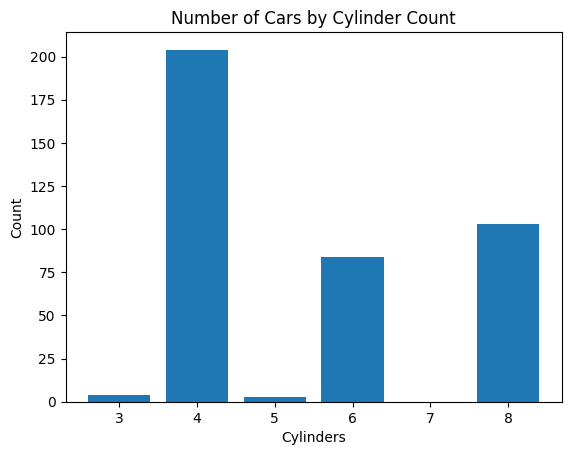

In [ ]:
plt.bar(cylinders_count['cylinders'], cylinders_count['count'])
plt.xlabel('Cylinders')
plt.ylabel('Count')
plt.title('Number of Cars by Cylinder Count')
plt.show()

In [43]:
average_mpg_by_cylinders = df.groupby('cylinders')['mpg'].mean().reset_index()
average_mpg_by_cylinders

,cylinders,mpg
0,3,20.550000
1,4,29.286765
2,5,27.366667
3,6,19.985714
4,8,14.963107


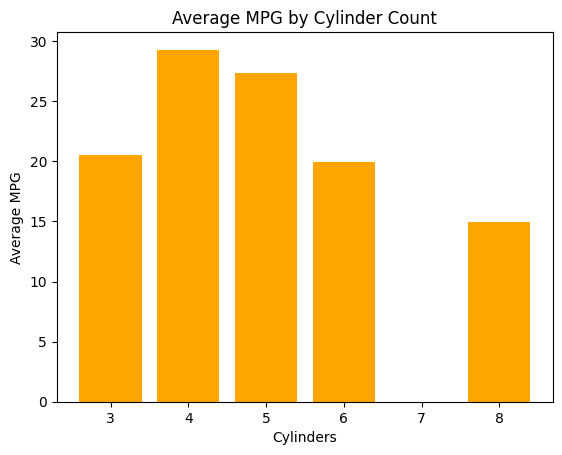

In [44]:
plt.bar(average_mpg_by_cylinders['cylinders'], average_mpg_by_cylinders['mpg'], color='orange')
plt.xlabel('Cylinders')
plt.ylabel('Average MPG')
plt.title('Average MPG by Cylinder Count')
plt.show()

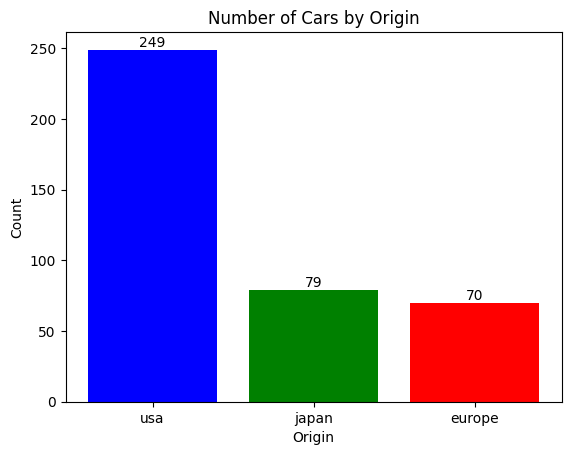

In [52]:
origin_counts = df['origin'].value_counts().reset_index()

plt.bar(origin_counts['origin'], origin_counts['count'], color=['blue', 'green', 'red'])

for i, count in enumerate(origin_counts['count']):
    plt.text(i, count, str(count), ha='center', va='bottom')

plt.xlabel('Origin')
plt.ylabel('Count')
plt.title('Number of Cars by Origin')
plt.show()

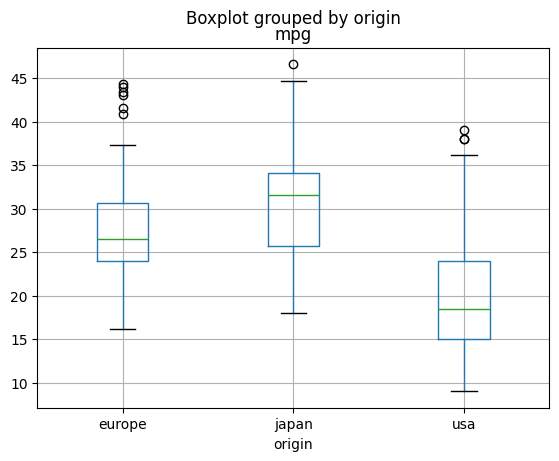

In [ ]:
# box plot of mpg by origin
df.boxplot(column='mpg', by='origin')
plt.show()

In [65]:
yearly_mpg = df.groupby('model_year')['mpg'].mean().reset_index()
yearly_mpg

,model_year,mpg
0,70,17.689655
1,71,21.250000
2,72,18.714286
3,73,17.100000
4,74,22.703704
5,75,20.266667
6,76,21.573529
7,77,23.375000
8,78,24.061111
9,79,25.093103


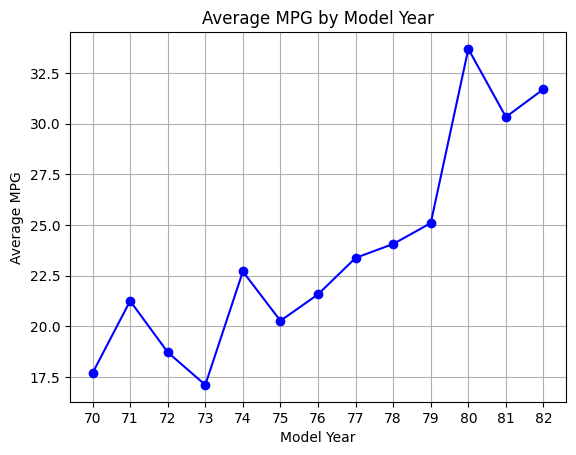

In [71]:
plt.plot(yearly_mpg['model_year'], yearly_mpg['mpg'], marker='o', linestyle='-', color='b')
plt.xlabel('Model Year')
plt.ylabel('Average MPG')
plt.title('Average MPG by Model Year')
plt.xticks(yearly_mpg['model_year'])  # Set x-ticks to be the model years
plt.grid()
plt.show()

<Axes: title={'center': 'mpg'}, xlabel='model_year'>

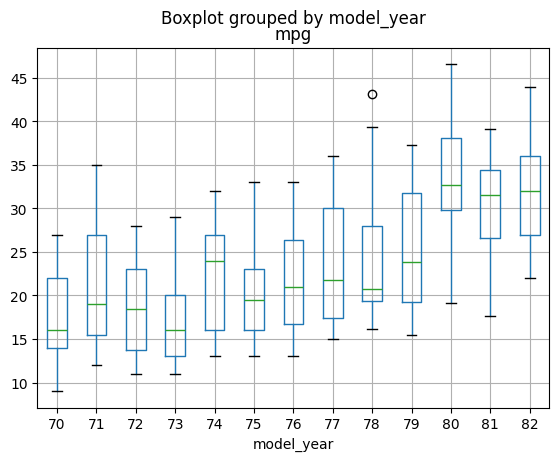

In [58]:
df.boxplot(column='mpg', by='model_year')

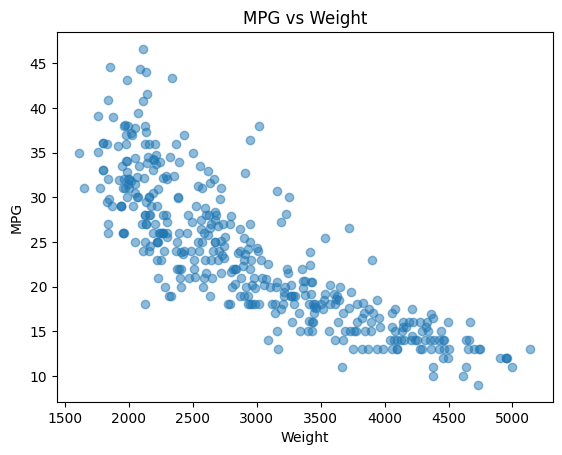

In [76]:
plt.scatter(df['weight'], df['mpg'], alpha=0.5)
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('MPG vs Weight')
plt.show()

In [ ]:
corr_value = df['weight'].corr(df['mpg'])

-0.8317409332443354


In [83]:
# correlation on multiple columns
correlation_matrix = df[['mpg', 'weight', 'horsepower', 'acceleration', 'displacement']].corr()
correlation_matrix

,mpg,weight,horsepower,acceleration,displacement
mpg,1.000000,-0.831741,-0.778427,0.420289,-0.804203
weight,-0.831741,1.000000,0.864538,-0.417457,0.932824
horsepower,-0.778427,0.864538,1.000000,-0.689196,0.897257
acceleration,0.420289,-0.417457,-0.689196,1.000000,-0.543684
displacement,-0.804203,0.932824,0.897257,-0.543684,1.000000


In [81]:
import seaborn as sns

<Axes: >

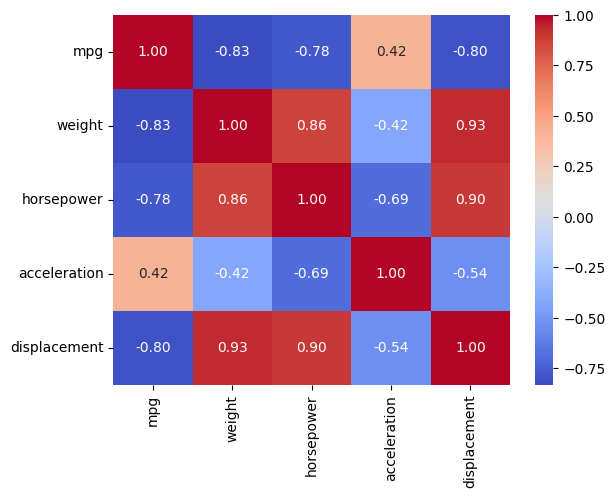

In [85]:
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

<Axes: xlabel='mpg', ylabel='Count'>

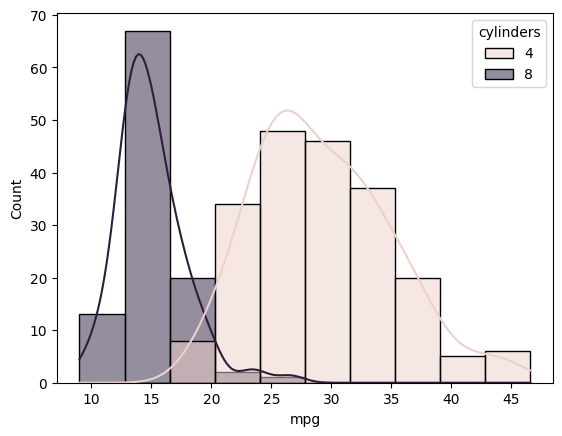

In [100]:
mpg_4cyl = df[df['cylinders'] == 4]['mpg']
mpg_8cyl = df[df['cylinders'] == 8]['mpg']

# histogram of mpg distribution by cylinders 3 and 4
sns.histplot(data=df[df['cylinders'].isin([4, 8])], x='mpg', hue='cylinders', bins=10, kde=True)